Every human genome is different. Any two people differ at about 4–5 million positions, and those differences, together with environment and chance, explain why we differ in height, disease risk and response to drugs. This chapter is about where that variation comes from (mutation), how it is passed on (inheritance), and how it changes over generations (drift and selection, which together drive evolution). The same ideas apply inside a tumour, where cells mutate, compete and evolve resistance to treatment.

:::eli5
You got one copy of each instruction book chapter from your mother and one from your father, so you have two versions of almost every gene. Sometimes a letter in a copy is changed by accident: a **mutation**. Most changes do nothing, some are harmful, a few are useful. Over many generations, useful changes tend to spread because their carriers have more children (**natural selection**), and in small groups some changes spread or vanish just by luck (**drift**). That slow change in the mix of versions in a population is **evolution**.
:::

## Genes, alleles and genotypes

Humans are **diploid**: we carry two copies of each chromosome (except the X and Y in males), one from each parent. So we have two copies of most genes. Different versions of a gene are called **alleles**. The pair of alleles a person carries is their **genotype**; the observable result is their **phenotype**.

| Genotype | Name | Example (sickle-cell gene *HBB*) |
|---|---|---|
| AA | homozygous | two normal copies: healthy |
| AS | heterozygous | one normal, one sickle copy: healthy carrier ("sickle-cell trait") |
| SS | homozygous | two sickle copies: sickle-cell disease |

An allele is **recessive** if it shows only when both copies carry it (sickle-cell disease, cystic fibrosis), and **dominant** if one copy is enough (Huntington's disease, inherited *BRCA1* breast cancer risk, which is dominant in families although each tumour has lost both copies).

Gregor Mendel worked out the basic rules in the 1860s by breeding pea plants:

1. **Segregation**: each parent passes on one of its two alleles, chosen at random.
2. **Independent assortment**: genes on different chromosomes are inherited independently.

A **Punnett square** lists all equally likely combinations. Try the first tab of the playground, including the X-linked case that explains why haemophilia and colour blindness are far more common in boys.

::playground animations/genetics_lab.html 620

Let's check Mendel's ratios by simulation, the way you'll check many probability claims in this course:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
from collections import Counter

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}
rng = np.random.default_rng(8)

def child(mum, dad):
    return "".join(sorted(rng.choice(list(mum)) + rng.choice(list(dad))))

kids = Counter(child("AS", "AS") for _ in range(100_000))
for g in ["AA", "AS", "SS"]:
    print(f"{g}: {kids[g] / 1e5:.3f}  (expected {[0.25, 0.5, 0.25][['AA', 'AS', 'SS'].index(g)]})")

# how variable is a real family? chance that 4 children of two carriers include no affected child
fams = np.array([sum(child("AS", "AS") == "SS" for _ in range(4)) for _ in range(20_000)])
R["none_of_4"] = f"{np.mean(fams == 0):.0%}"; R["two_plus"] = f"{np.mean(fams >= 2):.0%}"
print(f"families of 4: no affected child {np.mean(fams == 0):.1%} (exact 0.75^4 = {0.75 ** 4:.1%}), two or more {np.mean(fams >= 2):.1%}")

AA: 0.252  (expected 0.25)
AS: 0.497  (expected 0.5)
SS: 0.250  (expected 0.25)


families of 4: no affected child 31.2% (exact 0.75^4 = 31.6%), two or more 26.4%


The 1 : 2 : 1 ratio appears in large numbers, but individual families vary a lot: with two carrier parents and four children, 31% of families have no affected child at all and 26% have two or more. This is why genetic counsellors talk in probabilities per pregnancy, and why rare-disease genetics needs many families.

## Mutations: the source of variation

A **mutation** is any change in the DNA sequence. Two distinctions matter a lot in this course:

- **Germline** mutations are in eggs or sperm, so they are inherited and present in every cell of the child. **Somatic** mutations arise in one body cell and are passed only to its descendants. Cancer is driven by somatic mutations, sometimes on top of an inherited germline risk.
- The **size** of the change:

| Type | What changes | Typical detection |
|---|---|---|
| **SNV** (single-nucleotide variant) | one base | sequencing (chapter 5) |
| **Indel** | a few bases inserted or deleted | sequencing |
| **CNV** (copy-number variant) | a whole region duplicated or deleted | sequencing depth, arrays |
| **Structural variant** | inversions, translocations (pieces of chromosomes swapped) | long reads, karyotyping |
| **Aneuploidy** | whole chromosomes gained or lost | karyotype; very common in cancer |

A common SNV, carried by more than about 1% of a population, is called a **SNP** (single-nucleotide polymorphism, "snip"). Each person carries about 4–5 million SNVs relative to the reference genome, mostly common SNPs shared with many others.

Where do new mutations come from? Copying errors that escape proofreading (chapter P3), chemical damage (UV light, tobacco smoke, reactive oxygen), and the spontaneous loss of the methyl-C's amino group that turns it into T (chapter P6). How many new mutations does each child carry?

In [2]:
mu = 1.2e-8                     # germline mutation rate per base per generation (whole-genome sequencing of families)
diploid_bp = 2 * 3.1e9
expected = mu * diploid_bp
counts = rng.poisson(expected, 100_000)
print(f"expected new mutations per child: {expected:.0f}  (95% of children between {np.percentile(counts, 2.5):.0f} and {np.percentile(counts, 97.5):.0f})")
coding_fraction = 0.015
print(f"of which in protein-coding sequence: about {expected * coding_fraction:.1f}")
R["dnm"] = f"{expected:.0f}"; R["dnm_coding"] = f"{expected * coding_fraction:.0f}"

expected new mutations per child: 74  (95% of children between 58 and 92)
of which in protein-coding sequence: about 1.1


Each child carries about 74 brand-new mutations that neither parent had, about 1 of them in protein-coding sequence. Most are harmless. But because every child gets a fresh set, new (**de novo**) mutations are a major cause of severe childhood genetic disorders, and finding them is a routine job of clinical sequencing. The number also rises with the father's age, because sperm-making cells keep dividing throughout life.

## Populations: allele frequencies and Hardy–Weinberg

Population genetics tracks how common each allele is. If an allele has frequency $p$ and the other $q = 1 - p$, and people pair up at random with respect to this gene, then genotypes follow the **Hardy–Weinberg** proportions:

:::math
$$\text{AA}: p^2, \qquad \text{Aa}: 2pq, \qquad \text{aa}: q^2.$$

This holds when there is random mating, no selection, no migration, no new mutation and a large population. It is a null model: a deviation hints that one of those assumptions is broken (or that the genotyping has errors, which is how Hardy–Weinberg is used for quality control in genetic studies).
:::

A practical consequence for recessive diseases: almost all copies of the disease allele are hidden in healthy carriers.

In [3]:
for disease, q in [("cystic fibrosis (Europe)", 0.02), ("sickle-cell (parts of West Africa)", 0.10), ("Tay-Sachs (general population)", 0.004)]:
    p = 1 - q
    print(f"{disease:36s} affected {q * q:8.4%}   carriers {2 * p * q:6.2%}   carriers per affected person {2 * p * q / (q * q):5.0f}")
R["cf_carrier"] = f"1 in {1 / (2 * 0.98 * 0.02):.0f}"; R["cf_aff"] = f"1 in {1 / 0.02 ** 2:,.0f}"

cystic fibrosis (Europe)             affected  0.0400%   carriers  3.92%   carriers per affected person    98
sickle-cell (parts of West Africa)   affected  1.0000%   carriers 18.00%   carriers per affected person    18
Tay-Sachs (general population)       affected  0.0016%   carriers  0.80%   carriers per affected person   498


With a cystic fibrosis allele frequency of 2%, about 1 in 2,500 people are affected, but 1 in 26 is a carrier. Selection against the affected few barely touches an allele that hides in so many healthy carriers, which is one reason harmful recessive alleles persist.

## Drift: evolution by chance

Each generation's genes are a sample of the previous generation's. In a finite population, sampling alone changes allele frequencies at random: **genetic drift**. The standard model is the **Wright–Fisher model**: a population of $N$ diploid individuals ($2N$ gene copies) where each new generation draws its $2N$ copies at random, with replacement, from the last.

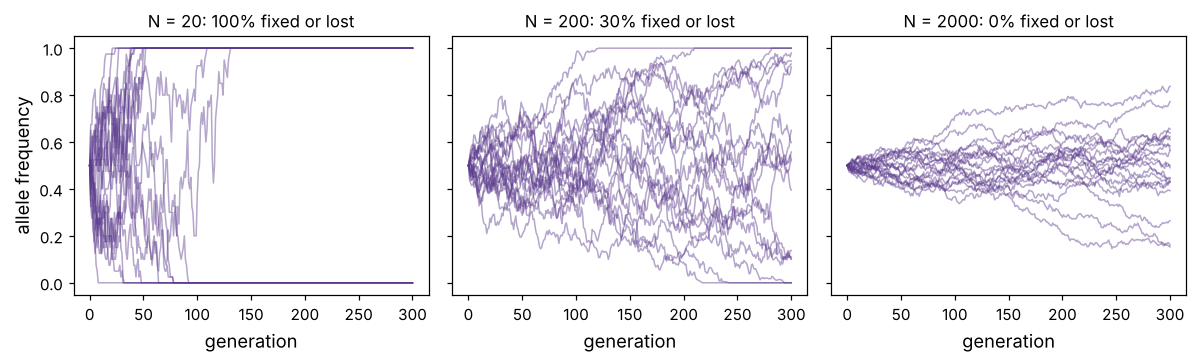

In [4]:
def wright_fisher(N, p0, gens, s=0.0, reps=1):
    """Allele frequency trajectories. s = relative fitness advantage of the allele."""
    p = np.full(reps, p0, float)
    out = [p.copy()]
    for _ in range(gens):
        w = p * (1 + s) / (p * (1 + s) + (1 - p))          # selection shifts the sampling probability
        p = rng.binomial(2 * N, w) / (2 * N)               # drift: random sampling of 2N copies
        out.append(p.copy())
    return np.array(out)

fig, axs = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, N in zip(axs, [20, 200, 2000]):
    traj = wright_fisher(N, 0.5, 300, reps=20)
    ax.plot(traj, color="#5b3a8c", alpha=0.45, lw=1)
    ax.set_title(f"N = {N}: {np.mean(traj[-1] == 0) + np.mean(traj[-1] == 1):.0%} fixed or lost", fontsize=11)
    ax.set_xlabel("generation")
axs[0].set_ylabel("allele frequency")
save_fig("drift"); plt.show()

![Figure P8-1. Twenty Wright–Fisher populations each, starting at 50%, for three population sizes. In small populations, drift quickly drives alleles to fixation (100%) or loss (0%); in large ones, frequencies wander slowly.](images/drift.png)

Drift is strong in small populations and weak in large ones: frequencies wander by roughly $\sqrt{p(1-p)/2N}$ per generation. This explains why some rare diseases are common in small or founder populations (Tay-Sachs in Ashkenazi Jews, Finnish disease heritage), and, in Part 5, why random genetic drift happens among the cells of a tumour too.

## Selection: evolution with a direction

If carriers of an allele have, on average, more surviving children (higher **fitness**), the allele tends to spread. The strength of selection is the relative advantage $s$: $s = 0.01$ means 1% more offspring. Starting rare, how often does a beneficial allele survive drift?

In [5]:
N, s, reps = 1000, 0.02, 4000
traj = wright_fisher(N, 1 / (2 * N), 3000, s=s, reps=reps)     # one new mutant copy
fixed = np.mean(traj[-1] == 1)
print(f"new beneficial mutation (s = {s}) in N = {N}: fixed in {fixed:.1%} of runs; theory ≈ 2s = {2 * s:.0%}")
Nn = 100                                                         # a smaller population, so neutral fixation is common enough to count
neutral = np.mean(wright_fisher(Nn, 1 / (2 * Nn), 3000, reps=20_000)[-1] == 1)
print(f"a neutral new mutation in N = {Nn}: fixed in {neutral:.2%} of runs; theory 1/2N = {1 / (2 * Nn):.2%}")
R["fix_ben"] = f"{fixed:.1%}"; R["fix_neu"] = f"{neutral:.2%}"

new beneficial mutation (s = 0.02) in N = 1000: fixed in 3.6% of runs; theory ≈ 2s = 4%


a neutral new mutation in N = 100: fixed in 0.56% of runs; theory 1/2N = 0.50%


A new mutation with a 2% advantage still disappears most of the time: it is fixed in only about 3.6% of runs, close to the classic approximation $2s$ (Haldane, 1927), because while it exists in one or a few copies it is at the mercy of chance. A neutral mutation is fixed with probability $1/2N$: in a population of 100 that is 0.5%, and the simulation gives 0.56%. Most evolution at the DNA level is the drift of nearly neutral changes, while selection acts on the few that matter.

The second tab of the playground lets you vary $N$, $s$ and the starting frequency.

### Sickle cell and malaria: balancing selection

The sickle-cell allele is common in regions with malaria. Why would a disease allele be common? Carriers (AS) are healthy *and* resist severe malaria. So in a malaria region, AS has the highest fitness, AA is hit by malaria, and SS by sickle-cell disease. Neither allele can win, and the frequency settles at a balance:

:::math
If AA has fitness $1 - s_1$, AS has fitness 1 and SS has fitness $1 - s_2$, the sickle allele frequency settles at
$$q^* = \frac{s_1}{s_1 + s_2}.$$
:::

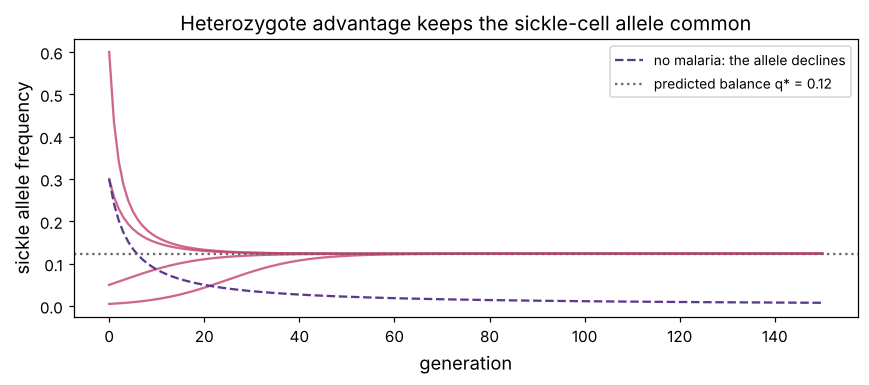

In [6]:
def selection_genotypes(q0, w_AA, w_AS, w_SS, gens=150):
    q, out = q0, [q0]
    for _ in range(gens):
        p = 1 - q
        wbar = p * p * w_AA + 2 * p * q * w_AS + q * q * w_SS
        q = (p * q * w_AS + q * q * w_SS) / wbar                 # frequency of S among the survivors' gametes
        out.append(q)
    return np.array(out)

s1, s2 = 0.12, 0.85                       # malaria cost to AA; sickle-cell disease cost to SS (illustrative)
fig, ax = plt.subplots(figsize=(8, 3.6))
for q0 in [0.005, 0.05, 0.3, 0.6]:
    ax.plot(selection_genotypes(q0, 1 - s1, 1.0, 1 - s2), color="#c2416b", alpha=0.8)
ax.plot(selection_genotypes(0.3, 1.0, 1.0, 1 - s2), color="#5b3a8c", ls="--", label="no malaria: the allele declines")
ax.axhline(s1 / (s1 + s2), color="0.4", ls=":", label=f"predicted balance q* = {s1 / (s1 + s2):.2f}")
ax.set_xlabel("generation"); ax.set_ylabel("sickle allele frequency"); ax.legend(fontsize=9)
ax.set_title("Heterozygote advantage keeps the sickle-cell allele common")
save_fig("sickle_balance"); plt.show()
R["qstar"] = f"{s1 / (s1 + s2):.2f}"

![Figure P8-2. With malaria, the sickle allele rises or falls to the same balance point from any starting frequency (red). Without malaria (purple, dashed), carriers have no advantage and the allele slowly declines.](images/sickle_balance.png)

From any starting point the frequency converges to about 0.12, in line with real frequencies of 10–20% in parts of Africa. The same kind of reasoning, an allele that is good in one context and bad in another, turns up in drug resistance: a mutation that protects a cancer cell from a drug may slow its growth when the drug is absent, which is the basis of "adaptive therapy" (chapter 19).

## Reading evolution in sequences

All living things descend from a common ancestor. As two lineages separate, each accumulates its own mutations, so the number of differences between their genes grows roughly with time: the **molecular clock**. Let's compare the β-globin protein (the *HBB* product) across species. We downloaded the sequences from UniProt, plus human α-globin, which arose from a duplication of an ancestral globin gene roughly 450 million years ago.

In [7]:
from Bio import SeqIO
from Bio import Align
from Bio.Align import substitution_matrices

recs = list(SeqIO.parse("datasets/hbb_orthologs.fasta", "fasta"))
names = {"HBB_HUMAN": "human", "HBB_PANTR": "chimpanzee", "HBB1_MOUSE": "mouse", "HBB_CHICK": "chicken", "HBB_PIG": "pig",
         "HBB1_DANRE": "zebrafish", "HBB_BOVIN": "cow", "HBB_HORSE": "horse", "HBA_HUMAN": "human α-globin"}
labels = [names[r.id.split("|")[2]] for r in recs]
seqs = [str(r.seq) for r in recs]

aligner = Align.PairwiseAligner(mode="global", open_gap_score=-10, extend_gap_score=-0.5)
aligner.substitution_matrix = substitution_matrices.load("BLOSUM62")
def identity(a, b):
    aln = aligner.align(a, b)[0]
    matches = sum(x == y for x, y in zip(aln[0], aln[1]) if x != "-" and y != "-")
    return matches / min(len(a), len(b))

n = len(seqs)
D = np.zeros((n, n))
for i in range(n):
    for j in range(i + 1, n):
        D[i, j] = D[j, i] = 1 - identity(seqs[i], seqs[j])
h = labels.index("human")
for k in np.argsort(D[h]):
    print(f"{labels[k]:16s} {100 * (1 - D[h, k]):5.1f}% identical to human β-globin")
R["chimp_id"] = f"{100 * (1 - D[h, labels.index('chimpanzee')]):.0f}"
R["mouse_id"] = f"{100 * (1 - D[h, labels.index('mouse')]):.0f}"
R["fish_id"] = f"{100 * (1 - D[h, labels.index('zebrafish')]):.0f}"
R["alpha_id"] = f"{100 * (1 - D[h, labels.index('human α-globin')]):.0f}"

human            100.0% identical to human β-globin
chimpanzee       100.0% identical to human β-globin
pig               85.0% identical to human β-globin
cow               84.8% identical to human β-globin
horse             83.6% identical to human β-globin
mouse             80.3% identical to human β-globin
chicken           69.4% identical to human β-globin
zebrafish         51.7% identical to human β-globin
human α-globin    45.8% identical to human β-globin


Human and chimpanzee β-globin are 100% identical (the proteins are in fact identical), human and mouse 80%, human and zebrafish 52%. Human α-globin is only 46% identical to human β-globin: the duplication is older than the split between fish and mammals. Turning such a distance table into a tree is the job of **phylogenetics** (chapter 3). Here is the simplest method, **UPGMA**, which repeatedly joins the two closest groups:

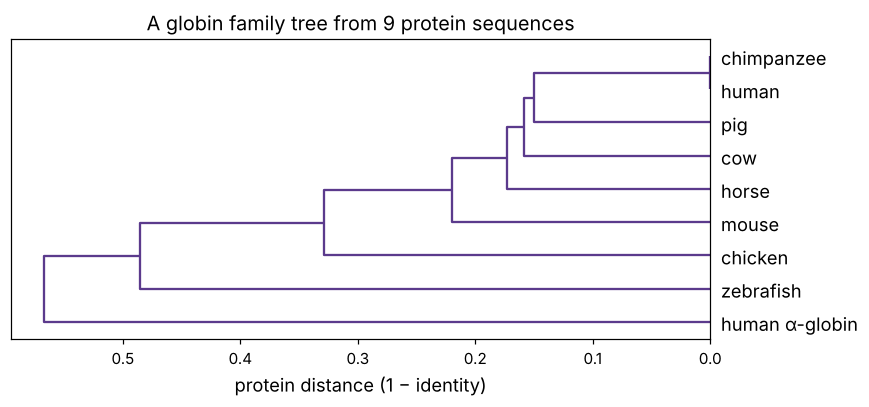

In [8]:
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
Z = linkage(squareform(D), method="average")      # average linkage = UPGMA
fig, ax = plt.subplots(figsize=(8, 3.8))
dendrogram(Z, labels=labels, orientation="left", ax=ax, color_threshold=0, above_threshold_color="#5b3a8c")
ax.set_xlabel("protein distance (1 − identity)"); ax.set_title("A globin family tree from 9 protein sequences")
save_fig("globin_tree"); plt.show()

![Figure P8-3. A tree built from pairwise differences between globin proteins. Mammals cluster together, chicken and fish branch off earlier, and α-globin sits outside all the β-globins because the gene duplication predates the split between these animals. (The position of mouse is an artefact, explained in the text.)](images/globin_tree.png)

From nothing but protein sequences, the tree recovers most of the known relationships: human and chimpanzee together, mammals together, then bird, then fish, then the older α/β duplication. One detail is wrong. Mice are really more closely related to primates than pigs, cows and horses are, but here mouse branches off first. Rodent genes evolve faster (rodents have short generations), and UPGMA assumes every lineage ticks at the same rate, so a fast lineage looks older than it is. Chapter 3 introduces tree methods that don't make that assumption. Genes in different species descended from one ancestral gene by speciation are **orthologs**; copies within one genome made by duplication (like α- and β-globin) are **paralogs**. The distinction matters whenever you transfer knowledge from a mouse experiment to a human patient.

## Complex traits and GWAS

Most traits (height, blood pressure, risk of type 2 diabetes or breast cancer) are **polygenic**: influenced by thousands of variants of small effect, plus environment. They are studied by **genome-wide association studies** (GWAS): genotype hundreds of thousands of people at millions of SNPs and test, SNP by SNP, whether one allele is more common in people with the trait. With millions of tests, the significance threshold is very strict, conventionally $p < 5 \times 10^{-8}$. Summing the small effects across a genome gives a **polygenic risk score**. Chapter 5 works with real variant data.

:::idea
A tumour is an evolving population. Its cells acquire somatic mutations (variation), some mutations help a cell divide faster or survive treatment (selection), and the many neutral ones hitch-hike or drift. Every idea in this chapter, from mutation rates to fixation probabilities to balancing selection, reappears in cancer genomics (chapter 20) and tumour evolution (chapter 19).
:::

## Summary

| Idea | One line |
|---|---|
| Alleles and genotype | two copies of each gene; dominant, recessive, X-linked |
| Mutation | SNVs, indels, CNVs, structural; germline vs somatic; ~70 new per child |
| Hardy–Weinberg | genotype frequencies p², 2pq, q² under random mating |
| Drift | random change in allele frequency; strongest in small populations |
| Selection | fitness differences push frequencies; new beneficial alleles are often still lost |
| Molecular clock | sequence differences grow with time; distances make trees |

:::check
1. Two parents are both carriers of a recessive disease. What is the chance their third child is affected, if the first two were not? *(Still 1/4: each child is independent.)*
2. An allele has frequency 0.1. What fraction of people are heterozygous under Hardy–Weinberg? *(2 × 0.1 × 0.9 = 18%.)*
3. Why are new beneficial mutations usually lost? *(While rare, they are at the mercy of drift; fixation probability is only about 2s.)*
4. What is the difference between germline and somatic mutations? *(Germline: inherited, in every cell. Somatic: arise in one body cell and its descendants.)*
5. Are human α- and β-globin orthologs or paralogs? *(Paralogs: they arose by duplication within one lineage.)*
:::

:::exercise
Use the Wright–Fisher function to estimate the fixation probability of a new mutation with advantage $s = 0.01$ in populations of $N$ = 50, 500 and 5000. Compare with Kimura's formula $P_\text{fix} = \dfrac{1 - e^{-2s}}{1 - e^{-4Ns}}$. For which population sizes does selection "work"?
:::

<details><summary>Solution</summary>

In [9]:
s = 0.01
for N in [50, 500, 5000]:
    sim = np.mean(wright_fisher(N, 1 / (2 * N), 20 * N, s=s, reps=4000)[-1] == 1)
    kimura = (1 - np.exp(-2 * s)) / (1 - np.exp(-4 * N * s))
    print(f"N = {N:5d}: simulated {sim:.4f}, Kimura {kimura:.4f}, neutral 1/2N = {1 / (2 * N):.4f}")

N =    50: simulated 0.0217, Kimura 0.0229, neutral 1/2N = 0.0100


N =   500: simulated 0.0213, Kimura 0.0198, neutral 1/2N = 0.0010


N =  5000: simulated 0.0225, Kimura 0.0198, neutral 1/2N = 0.0001


For N = 50 (4Ns = 2) the fixation probability is only modestly above the neutral value: drift dominates. For N = 500 and 5000 it approaches 2s = 0.02, far above neutral: selection dominates once $4Ns \gg 1$. This is why small populations, including the small founding populations of cells that seed a metastasis, can carry harmful mutations to high frequency by chance.

</details>